In [7]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/Price_Agriculture_commodities_Week.csv')

print(df.head())

     State District    Market              Commodity      Variety Grade  \
0  Gujarat   Amreli  Damnagar  Bhindi(Ladies Finger)       Bhindi   FAQ   
1  Gujarat   Amreli  Damnagar                Brinjal        Other   FAQ   
2  Gujarat   Amreli  Damnagar                Cabbage      Cabbage   FAQ   
3  Gujarat   Amreli  Damnagar            Cauliflower  Cauliflower   FAQ   
4  Gujarat   Amreli  Damnagar      Coriander(Leaves)    Coriander   FAQ   

  Arrival_Date  Min Price  Max Price  Modal Price  
0   27-07-2023     4100.0     4500.0       4350.0  
1   27-07-2023     2200.0     3000.0       2450.0  
2   27-07-2023     2350.0     3000.0       2700.0  
3   27-07-2023     7000.0     7500.0       7250.0  
4   27-07-2023     8400.0     9000.0       8850.0  


In [8]:
commodity_df = df[df['Commodity'] == 'Brinjal']

print(commodity_df.head())

               State   District    Market Commodity  Variety Grade  \
1            Gujarat     Amreli  Damnagar   Brinjal    Other   FAQ   
18  Himachal Pradesh     Kangra  Palampur   Brinjal  Brinjal   FAQ   
58            Kerala  Alappuzha  Harippad   Brinjal    Other   FAQ   
69          Nagaland     Kohima   Jalukie   Brinjal    Other   FAQ   
81            Odisha  Dhenkanal    Hindol   Brinjal  Brinjal   FAQ   

   Arrival_Date  Min Price  Max Price  Modal Price  
1    27-07-2023     2200.0     3000.0       2450.0  
18   27-07-2023     5000.0     5200.0       5100.0  
58   27-07-2023     3000.0     3500.0       3000.0  
69   27-07-2023     8600.0     8800.0       8700.0  
81   27-07-2023     4000.0     5000.0       4500.0  


In [13]:
commodity_df = df[df['Commodity'] == 'Brinjal']

commodity_df['Arrival_Date'] = pd.to_datetime(
    commodity_df['Arrival_Date'],
    dayfirst=True
)

commodity_df = commodity_df.sort_values('Arrival_Date')

price_series = commodity_df.groupby(
    'Arrival_Date'
)['Modal Price'].mean()

print(price_series.head())

print(len(price_series))

Arrival_Date
2023-07-27    3312.500000
2023-07-28    2763.730159
2023-07-29    2846.192053
2023-07-30    2792.894737
2023-07-31    2930.585586
Name: Modal Price, dtype: float64
7


In [14]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(
    np.array(price_series).reshape(-1,1)
)

print(scaled_data[:5])

[[0.30412   ]
 [0.        ]
 [0.04569914]
 [0.01616257]
 [0.09246877]]


In [17]:
sequence_length = 3

X = []
y = []

for i in range(sequence_length, len(scaled_data)):

    X.append(
        scaled_data[i-sequence_length:i]
    )

    y.append(
        scaled_data[i]
    )

X = np.array(X)
y = np.array(y)

print(X.shape)
print(y.shape)

(4, 3, 1)
(4, 1)


In [16]:
print(df['Commodity'].unique())

<StringArray>
['Bhindi(Ladies Finger)',               'Brinjal',               'Cabbage',
           'Cauliflower',     'Coriander(Leaves)',         'Ginger(Green)',
          'Green Chilli',                  'Guar',                 'Lemon',
                'Tomato',
 ...
        'Patti Calcutta',                'Raibel',           'Rose(Local)',
     'Tube Rose(Double)',     'Tube Rose(Single)',                  'Bull',
                  'Calf',                   'Cow',            'He Buffalo',
           'She Buffalo']
Length: 234, dtype: str


In [18]:
import torch
import torch.nn as nn

X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

print(X_tensor.shape)
print(y_tensor.shape)

torch.Size([4, 3, 1])
torch.Size([4, 1])


In [19]:
class LSTMModel(nn.Module):

    def __init__(self):
        super(LSTMModel, self).__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=50,
            batch_first=True
        )

        self.fc = nn.Linear(50, 1)

    def forward(self, x):

        out, _ = self.lstm(x)

        out = out[:, -1, :]

        out = self.fc(out)

        return out

In [20]:
model = LSTMModel()

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [21]:
epochs = 100

for epoch in range(epochs):

    outputs = model(X_tensor)

    loss = criterion(outputs, y_tensor)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(
            f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}'
        )

Epoch [10/100], Loss: 0.2475
Epoch [20/100], Loss: 0.1984
Epoch [30/100], Loss: 0.1661
Epoch [40/100], Loss: 0.1591
Epoch [50/100], Loss: 0.1598
Epoch [60/100], Loss: 0.1579
Epoch [70/100], Loss: 0.1577
Epoch [80/100], Loss: 0.1571
Epoch [90/100], Loss: 0.1566
Epoch [100/100], Loss: 0.1561


In [22]:
last_sequence = scaled_data[-sequence_length:]

last_sequence = torch.tensor(
    last_sequence,
    dtype=torch.float32
).unsqueeze(0)

prediction = model(last_sequence)

predicted_price = scaler.inverse_transform(
    prediction.detach().numpy()
)

print(
    "Predicted Brinjal Price:",
    predicted_price[0][0]
)

Predicted Brinjal Price: 3554.0024


In [24]:
import matplotlib.pyplot as plt

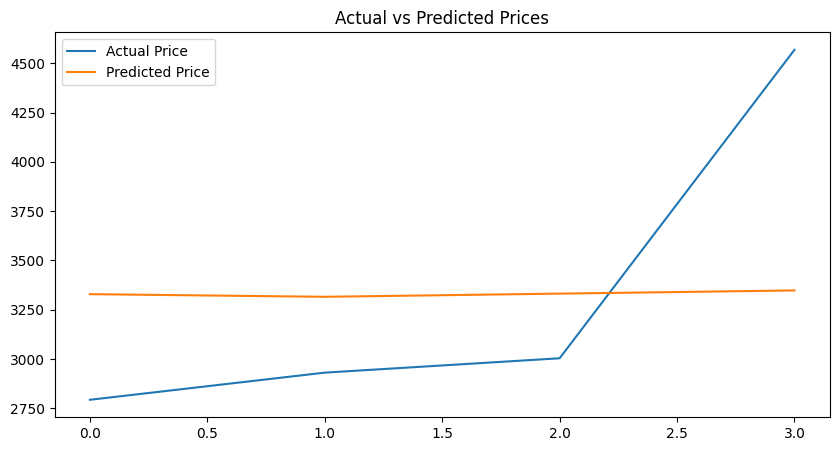

In [25]:
predictions = model(X_tensor).detach().numpy()

predictions = scaler.inverse_transform(predictions)

actual = scaler.inverse_transform(
    y.reshape(-1,1)
)

plt.figure(figsize=(10,5))

plt.plot(actual, label='Actual Price')

plt.plot(predictions, label='Predicted Price')

plt.legend()

plt.title(
    "Actual vs Predicted Prices"
)

plt.show()

In [26]:
import torch

torch.save(model.state_dict(), 'brinjal_lstm_model.pth')

print("Model Saved Successfully")

Model Saved Successfully


In [27]:
import torch
import torch.nn as nn
import numpy as np

In [28]:
class LSTMModel(nn.Module):

    def __init__(self):
        super(LSTMModel, self).__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=50,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(50, 1)

    def forward(self, x):

        out, _ = self.lstm(x)

        out = self.fc(out[:, -1, :])

        return out

In [29]:
model = LSTMModel()

model.load_state_dict(
    torch.load('brinjal_lstm_model.pth')
)

model.eval()

LSTMModel(
  (lstm): LSTM(1, 50, batch_first=True)
  (fc): Linear(in_features=50, out_features=1, bias=True)
)

In [30]:
future_input = torch.tensor(
    X[-1:].astype(np.float32)
)

prediction = model(future_input)

prediction = prediction.detach().numpy()

predicted_price = scaler.inverse_transform(
    prediction
)

print(predicted_price)

[[3347.504]]


In [32]:
commodities = [
    'Brinjal',
    'Cabbage',
    'Cauliflower',
    'Rice',
    'Wheat'
]

In [33]:
for commodity in commodities:

    print(f"Training for {commodity}")

    commodity_df = df[df['Commodity'] == commodity]

    commodity_df['Arrival_Date'] = pd.to_datetime(
        commodity_df['Arrival_Date'],
        dayfirst=True
    )

    commodity_df = commodity_df.sort_values(
        'Arrival_Date'
    )

    price_series = commodity_df.groupby(
        'Arrival_Date'
    )['Modal Price'].mean()

    if len(price_series) < 5:

        print(f"Not enough data for {commodity}")
        continue

    scaler = MinMaxScaler()

    scaled_data = scaler.fit_transform(
        np.array(price_series).reshape(-1,1)
    )

    sequence_length = 3

    X = []
    y = []

    for i in range(sequence_length, len(scaled_data)):

        X.append(
            scaled_data[i-sequence_length:i]
        )

        y.append(
            scaled_data[i]
        )

    X = np.array(X)
    y = np.array(y)

    X_tensor = torch.tensor(
        X.astype(np.float32)
    )

    y_tensor = torch.tensor(
        y.astype(np.float32)
    )

    model = LSTMModel()

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01
    )

    epochs = 100

    for epoch in range(epochs):

        outputs = model(X_tensor)

        loss = criterion(outputs, y_tensor)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

    filename = f"{commodity.lower()}_lstm_model.pth"

    torch.save(
        model.state_dict(),
        filename
    )

    print(f"{commodity} model saved")

Training for Brinjal
Brinjal model saved
Training for Cabbage
Cabbage model saved
Training for Cauliflower
Cauliflower model saved
Training for Rice
Rice model saved
Training for Wheat
Wheat model saved


In [34]:
print(df[df['Commodity'].str.contains('on', case=False, na=False)]['Commodity'].unique())

<StringArray>
[                     'Lemon',                      'Onion',
               'Sponge gourd',        'Paddy(Dhan)(Common)',
                     'Cotton',  'Green Gram (Moong)(Whole)',
                'Onion Green',    'Pegeon Pea (Arhar Fali)',
             'Tender Coconut',                'Water Melon',
        'Karbuja(Musk Melon)',                  'Thondekai',
 'Green Gram Dal (Moong Dal)',                'Coconut Oil',
                    'Coconut',          'Long Melon(Kakri)',
               'Coconut Seed',              'Season Leaves',
              'Almond(Badam)',          'Cinamon(Dalchini)',
                  'Carnation']
Length: 21, dtype: str
